# Lab 11: Attention with an RNN

**Maan Ghamdi | 2240001433**

I classify questions into answer groups and inspect the learned attention weights. I complete both tasks below. I use the full dataset for this classroom demonstration; training accuracy is not a measure of performance on unseen questions.

**Run:** Keep the CSV next to this notebook, select a Python kernel with PyTorch, pandas and Matplotlib installed, then restart the kernel and run all cells. See README.md for setup.

### How attention works

I embed each token, process the sequence with an RNN, score each hidden state, and apply softmax across the real tokens. The weighted sum of hidden states becomes the input to an answer-group classifier. This is attention pooling for classification, rather than a generative encoder-decoder model. Padding receives zero attention.

## Step 1 — Import libraries

In [1]:
import re
import random
import sys
from pathlib import Path
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")
print("Device: CPU | Seed:", SEED)

Python 3.12.10 | PyTorch 2.15.0+cpu | pandas 3.1.0 | Matplotlib 3.11.2
Device: CPU | Seed: 42


## Step 2 — Load the dataset

I load the supplied CSV from the working directory. In Colab, I upload the CSV to the Files pane before running this notebook.

In [2]:
dataset_path = Path("Lab_11_QnA_Dataset.csv")
if not dataset_path.is_file():
    raise FileNotFoundError("Place Lab_11_QnA_Dataset.csv in the notebook's working folder (or upload it to Colab's Files pane).")
df = pd.read_csv(dataset_path)
assert {"question", "answer_id", "answer"}.issubset(df.columns)
assert not df[["question", "answer_id", "answer"]].isna().any().any()
assert df.groupby("answer_id")["answer"].nunique().eq(1).all()
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
def tokenize(text):
    return re.sub(r"[^a-z0-9\s]", "", text.lower()).split()

tokens = [tokenize(q) for q in df["question"]]
assert all(tokens), "Every question must contain at least one token."
word_index = {"<PAD>": 0, "<UNK>": 1}
for question_tokens in tokens:
    for word in question_tokens:
        if word not in word_index:
            word_index[word] = len(word_index)

X = pad_sequence([torch.tensor([word_index[w] for w in ws], dtype=torch.long)
                  for ws in tokens], batch_first=True, padding_value=0)
class_ids = sorted(df["answer_id"].unique().tolist())
id_to_class = {answer_id: i for i, answer_id in enumerate(class_ids)}
y = torch.tensor([id_to_class[a] for a in df["answer_id"]], dtype=torch.long)
answer_lookup = df.drop_duplicates("answer_id").set_index("answer_id")["answer"].to_dict()
print("Vocabulary size (including PAD and UNK):", len(word_index))
print("Input shape (questions, tokens):", tuple(X.shape))
print("First tokenized question:", tokens[0])

Vocabulary size (including PAD and UNK): 228
Input shape (questions, tokens): (168, 11)
First tokenized question: ['do', 'you', 'get', 'hurt']


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index), 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, len(class_ids))

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1)
        scores = scores.masked_fill(x.eq(0), float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()
print(model)

RNN(
  (emb): Embedding(228, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

Epoch  30/150 | loss: 0.3626
Epoch  60/150 | loss: 0.0202


Epoch  90/150 | loss: 0.0050
Epoch 120/150 | loss: 0.0029


Epoch 150/150 | loss: 0.0020
Training accuracy: 100.00% (not held-out accuracy)


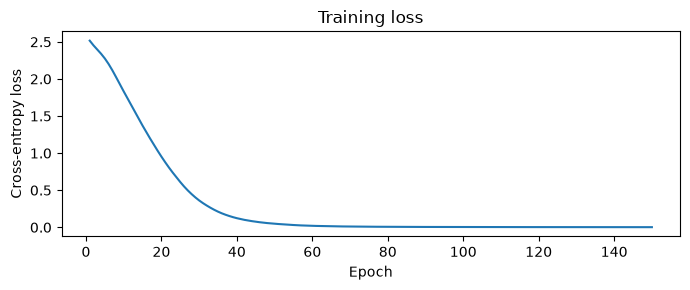

In [5]:
# I use 150 epochs to fit this small demonstration dataset.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []
model.train()
for epoch in range(150):
    optimizer.zero_grad(set_to_none=True)
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    assert torch.isfinite(loss), "Training loss must remain finite."
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (epoch + 1) % 30 == 0:
        print(f"Epoch {epoch + 1:3d}/150 | loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
    logits, all_weights = model(X)
    training_accuracy = (logits.argmax(1) == y).float().mean().item()
print(f"Training accuracy: {training_accuracy:.2%} (not held-out accuracy)")
plt.figure(figsize=(7, 3))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss")
plt.tight_layout()
plt.show()

## Step 6 — See attention

I use the same tokenizer for the chart labels and the model input. My helper plots real tokens only, identifies the highest-weight token, and shows the predicted answer. Task 1 uses this helper for three questions.

In [6]:
def show_attention(row_indices, title):
    model.eval()
    fig, axes = plt.subplots(len(row_indices), 1, figsize=(10, 3.5 * len(row_indices)), squeeze=False)
    records = []
    with torch.no_grad():
        predictions, weights = model(X[row_indices])
    for position, row_index in enumerate(row_indices):
        words = tokens[row_index]
        values = weights[position, :len(words)].tolist()
        peak = max(range(len(values)), key=values.__getitem__)
        predicted_id = class_ids[predictions[position].argmax().item()]
        ax = axes[position, 0]
        ax.bar(range(len(words)), values,
               color=["#e88c30" if j == peak else "#3679aa" for j in range(len(words))])
        ax.set_xticks(range(len(words)), words, rotation=25, ha="right")
        ax.set_ylabel("Attention weight")
        ax.set_ylim(0, 1.05)
        ax.set_title(df.loc[row_index, "question"])
        records.append({"Question": df.loc[row_index, "question"],
                        "Highest-attention word": words[peak], "Weight": values[peak],
                        "Predicted answer": answer_lookup[predicted_id],
                        "Correct": predicted_id == df.loc[row_index, "answer_id"]})
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()
    result = pd.DataFrame(records)
    display(result)
    return result

print("Attention visualization helper is ready.")

Attention visualization helper is ready.


## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

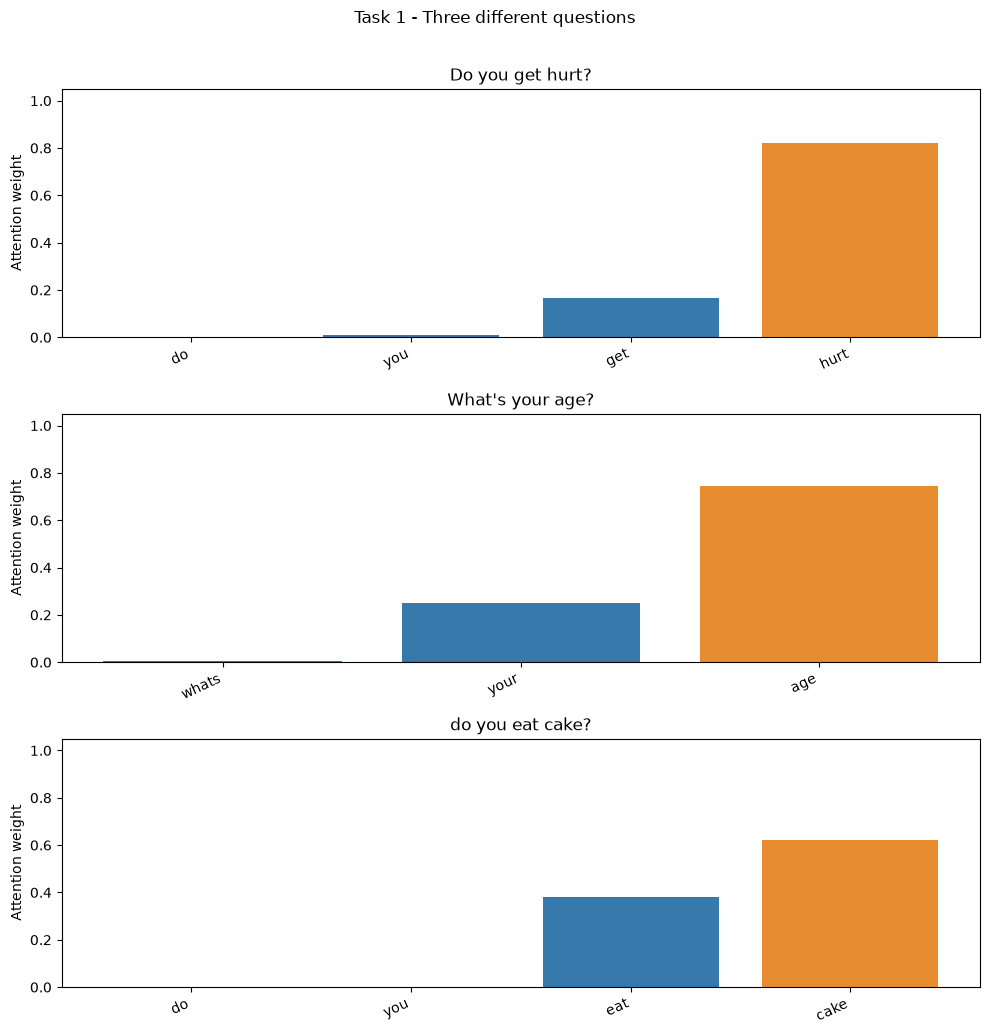

,Question,Highest-attention word,Weight,Predicted answer,Correct
0,Do you get hurt?,hurt,0.820762,I don't have a body.,True
1,What's your age?,age,0.744076,Age doesn't really apply to me.,True
2,do you eat cake?,cake,0.619762,I don't need to eat.,True


In [7]:
task1_rows = [0, 20, 98]
task1_results = show_attention(task1_rows, "Task 1 - Three different questions")

### My observations — Task 1

In my saved run, **hurt** has the highest weight (0.8208) in "Do you get hurt?", **age** has the highest weight (0.7441) in "What's your age?", and **cake** has the highest weight (0.6198) in "do you eat cake?". I find these words relevant: hurt points to a physical experience, age identifies the age topic, and cake identifies food. In the third question, "eat" is also important to a human reader, but my model gives more weight to the state at "cake". All three predicted answers match the dataset.

I interpret these weights as the model's allocation of weight to contextual RNN states. Each state includes information from preceding tokens, so a high weight on a word is not proof that the word alone caused the answer. These examples come from the training data.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

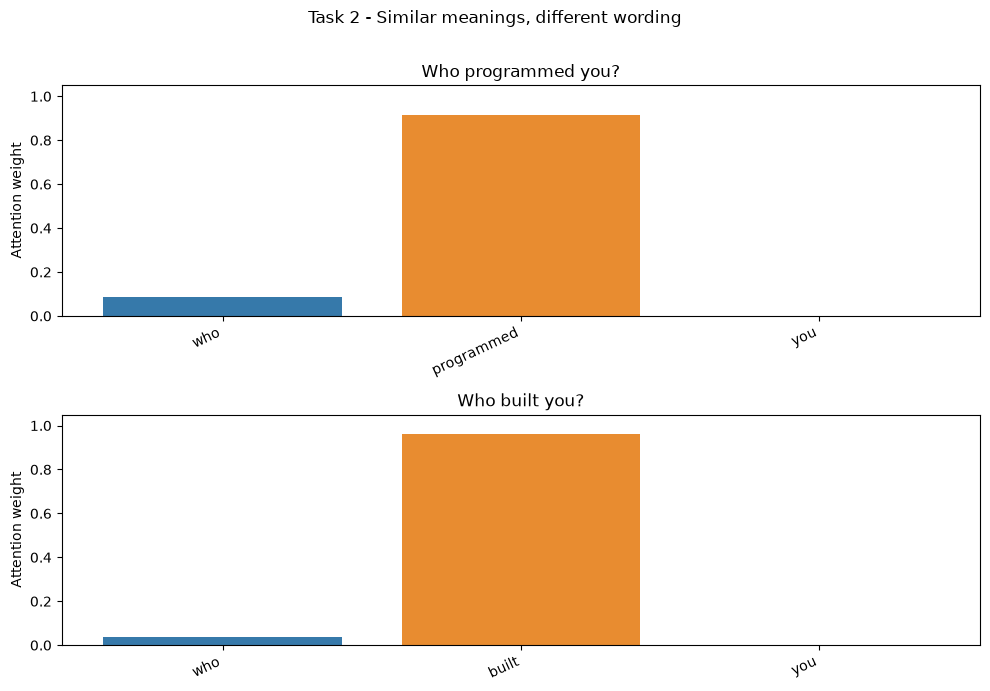

,Question,Highest-attention word,Weight,Predicted answer,Correct
0,Who programmed you?,programmed,0.913994,People created me.,True
1,Who built you?,built,0.963030,People created me.,True


In [8]:
# Both questions ask who created the assistant, using different verbs.
task2_rows = [42, 46]
assert df.loc[task2_rows, "answer_id"].nunique() == 1
task2_results = show_attention(task2_rows, "Task 2 - Similar meanings, different wording")

### My observations — Task 2

I compare "Who programmed you?" with "Who built you?" because both ask about the assistant's creator. In my saved run, **programmed** receives the highest weight (0.9140) in the first question and **built** receives the highest weight (0.9630) in the second. The highest-weight words are different tokens but serve a similar semantic role: both describe creation. My model predicts "People created me." for both questions. I observe a similar focus on the creation verb, with different numerical weights for the two phrasings.

I conclude that attention is learned and depends on both wording and context; it is not a fixed list of important keywords. Similar questions can lead to the same answer while distributing attention differently. I would need held-out questions and additional experiments to assess generalization.

## Verification

I check tensor dimensions, finite outputs, normalized attention, padding behavior, independence from other questions in a batch, and decreasing training loss.

In [9]:
# I check the properties that were incorrect or missing in the starter.
assert logits.shape == (len(df), len(class_ids))
assert all_weights.shape == X.shape
assert torch.isfinite(logits).all() and torch.isfinite(all_weights).all()
assert torch.allclose(all_weights.sum(1), torch.ones(len(df)), atol=1e-6)
assert torch.count_nonzero(all_weights[X.eq(0)]).item() == 0
with torch.no_grad():
    single_logits, _ = model(X[:1])
    padded_logits, _ = model(torch.cat([X[:1], torch.zeros((1, 3), dtype=torch.long)], dim=1))
assert torch.allclose(single_logits, logits[:1], atol=1e-5)
assert torch.allclose(single_logits, padded_logits, atol=1e-5)
assert loss_history[-1] < loss_history[0]
print("All checks passed: shapes, finite values, normalized attention, zero padding attention, batch independence, padding invariance, and decreasing loss.")

All checks passed: shapes, finite values, normalized attention, zero padding attention, batch independence, padding invariance, and decreasing loss.
